# Gaussian Naive Bayes profitability model

This notebook uses a simple sequence: load data, split data, fill missing values, train GaussianNB, evaluate the test data, and plot the results.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, average_precision_score, classification_report, ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

## Load and inspect the prepared records

The CSV has 150 predictor columns and the binary `profitable` target. Profit is 1 and Loss is 0. The classes are balanced because the source data was undersampled.

In [2]:
df = pd.read_csv("../dataset/clean_undersampled.csv", low_memory=False)
X = df.drop(columns=["profitable"])
y = df["profitable"]
print("Feature shape:", X.shape)
print("Class balance:\n", y.value_counts())

Feature shape: (549174, 150)
Class balance:
 profitable
0    274587
1    274587
Name: count, dtype: int64


## Create training and test sets

The test set is held out until the end. Stratification keeps the Profit/Loss proportions consistent.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=12, stratify=y)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 439339
Test rows: 109835


## Fill missing values and train GaussianNB

In order to fine tune the parameter used in the GaussianNB function, a GridSearchCV was used to compare different values of var_smoothing. Five-fold validation was used to compare the probability ranking of each setting. Based on those results, the following parameter was chosen for the active model.

The active model uses the previously selected value: var_smoothing 1e-12. The imputer addresses values with missing data by replacing them with the median of that column.

The search code can be viewed in the commented cell below. It is currently commented so the other code can be run as simply as possible.

In [4]:
# nb_search = GridSearchCV(
#     Pipeline([
#         ("imputer", SimpleImputer(strategy="median")),
#         ("model", GaussianNB()),
#     ]),
#     {"model__var_smoothing": np.logspace(-12, -6, 12)},
#     cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=12),
#     scoring="average_precision",
#     n_jobs=-1,
#     refit=False,
# )
# nb_search.fit(X_train, y_train)
# print("Best parameters:", nb_search.best_params_)
# Best parameters: {'model__var_smoothing': 1e-12}

In [5]:
imputer = SimpleImputer(strategy="median")
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)
model = GaussianNB(var_smoothing=1e-12)
model.fit(X_train_imputed, y_train)

,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-12
,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[219670.,219669.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.5,0.5]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,0.02826
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,150
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 150)","[[15749.22, 15.66, 2.39,..., 0.36, 2015.39, 15.8 ], [14151.98, 12.7 , 1.6 ,..., 0.3 , 2014.87, 16.4 ]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 150)","[[79560625.17, 24.85, 1.75,..., 0.26, 2.44, 56.53], [75233020.58, 20.65, 1.57,..., 0.24, 2.76, 56.2 ]]"


## Evaluate the held-out test data

After having used cross validation to select the smoothing parameter, the model can be trained as follows.

The fitted model is evaluated once on the held-out test data. The test data is transformed with the medians calculated from the training data and is not used during parameter selection.

In [6]:
test_probability = model.predict_proba(X_test_imputed)[:, 1]
test_prediction = model.predict(X_test_imputed)

print("Accuracy:", round(accuracy_score(y_test, test_prediction), 4))
print("Precision:", round(precision_score(y_test, test_prediction, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, test_prediction, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, test_prediction, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_probability), 4))
print("Average precision:", round(average_precision_score(y_test, test_probability), 4))
print(classification_report(y_test, test_prediction, target_names=["Loss", "Profit"], zero_division=0))

Accuracy: 0.6311
Precision: 0.6097
Recall: 0.7291
F1-score: 0.664
ROC-AUC: 0.6843
Average precision: 0.6679
              precision    recall  f1-score   support

        Loss       0.66      0.53      0.59     54917
      Profit       0.61      0.73      0.66     54918

    accuracy                           0.63    109835
   macro avg       0.64      0.63      0.63    109835
weighted avg       0.64      0.63      0.63    109835



## Plot the test results

The confusion matrix shows mistakes. ROC-AUC shows ranking quality. The precision-recall curve shows how precision and recall change across thresholds.

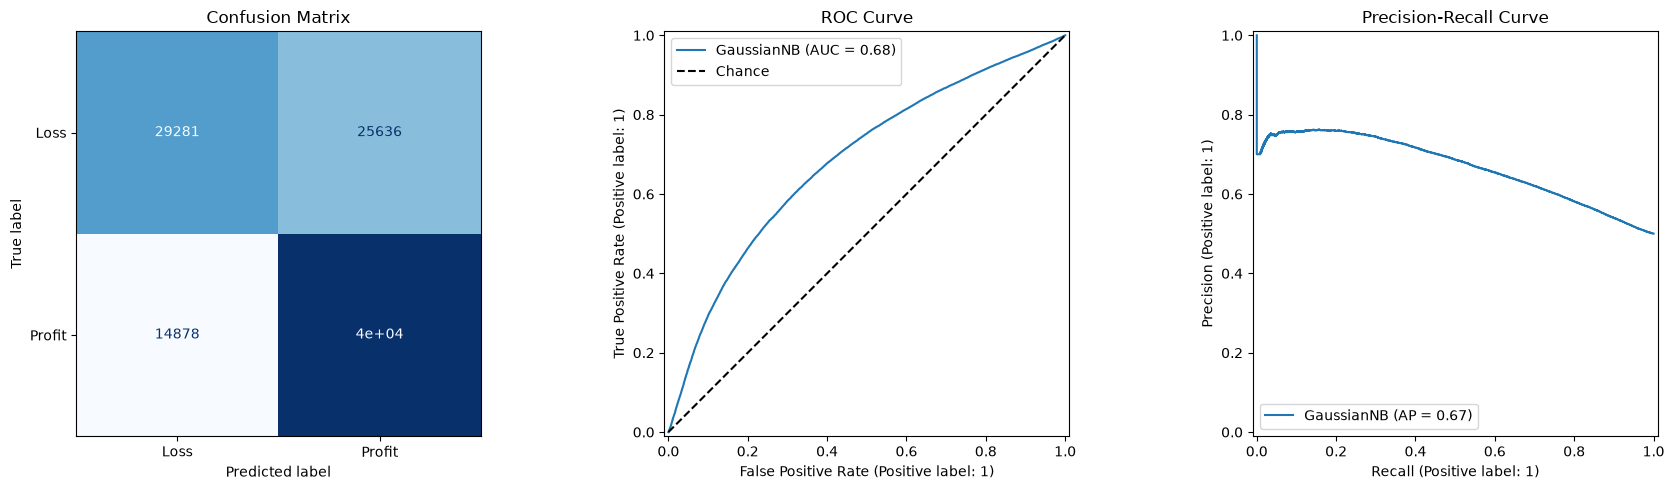

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ConfusionMatrixDisplay.from_predictions(y_test, test_prediction, display_labels=["Loss", "Profit"], cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Confusion Matrix")
RocCurveDisplay.from_predictions(y_test, test_probability, name="GaussianNB", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Chance")
axes[1].legend()
axes[1].set_title("ROC Curve")
PrecisionRecallDisplay.from_predictions(y_test, test_probability, name="GaussianNB", ax=axes[2])
axes[2].set_title("Precision-Recall Curve")
plt.tight_layout()
plt.show()